# Домашнее задание 8 (10 pts)

Сопряжённые градиенты, тяжёлый шарик и метод Нестерова. Схемы итераций — на слайдах лекции, в задании они не повторяются.

На неделе 7 градиентный спуск с шагом $1/L$ на $\mu$-сильно выпуклой задаче тратит порядка $\kappa=L/\mu$ итераций. У методов этой недели в оценке стоит $\sqrt{\kappa}$.

База сравнения всюду одна — градиентный спуск с шагом $1/L$. По горизонтали откладывайте число умножений на матрицу или число вызовов градиента: у этих методов его один на итерацию.

Графики и письменный вывод обязательны в каждом пункте. Без комментария баллы за пункт не ставятся.


In [2]:
import numpy as np
import matplotlib.pyplot as plt


## Задача 1 (4 pts). Стационарная температура пластины

Квадратная пластина $(0,1)^2$, на границе температура нулевая, внутри два нагревателя. В стационаре

$$
-\Delta u = f.
$$

На сетке $n\times n$ внутренних узлов с шагом $h=1/(n+1)$ пятиточечный шаблон даёт систему $\mathbf{A}\mathbf{u}=\mathbf{b}$ с $\mathbf{A}=\mathbf{A}^\top\succ 0$. Саму матрицу не хранят: `apply_A` по вектору длины $n^2$ возвращает $\mathbf{A}\mathbf{u}$. Одно такое умножение — одна итерация каждого метода ниже.

Собственные значения шаблона

$$
\lambda_{p,q}
=
4\sin^2\frac{p\pi}{2(n+1)}
+
4\sin^2\frac{q\pi}{2(n+1)},
\qquad p,q=1,\ldots,n.
$$

Крайние из них, они же $\mu$ и $L$ квадратичной задачи,

$$
\mu=\lambda_{1,1}=8\sin^2\frac{\pi}{2(n+1)},
\qquad
L=\lambda_{n,n}=8\cos^2\frac{\pi}{2(n+1)},
\qquad
\kappa=\frac{L}{\mu}.
$$

Минимизируется энергия

$$
f(\mathbf{u})=\tfrac12\mathbf{u}^\top\mathbf{A}\mathbf{u}-\mathbf{b}^\top\mathbf{u}.
$$

Её градиент $\mathbf{g}(\mathbf{u})=\mathbf{A}\mathbf{u}-\mathbf{b}$ — невязка системы, минимум совпадает с решением. За $f^\star$ возьмите значение в точке, куда сопряжённые градиенты приходят с относительной невязкой $10^{-12}$.

Рассмотрим методы с лекции: градиентный спуск идёт с шагом $1/L$, тяжёлый шарик с оптимальными параметрами и линейный метод сопряжённых градиентов.


1. **(1.5 pts)** Возьмите $n=32$ и старт в нуле. Доведите относительную невязку $\|\mathbf{g}_k\|/\|\mathbf{g}_0\|$ до $10^{-6}$, бюджет — 8000 итераций.

   На одном графике с логарифмической осью $y$ покажите невязку трёх методов. В таблице приведите число итераций, $\kappa$ и $\sqrt{\kappa}$.

   Отдельно постройте $f(\mathbf{u}_k)-f^\star$ для сопряжённых градиентов и для тяжёлого шарика. Для каждого метода ответьте: убывает ли значение на каждом шаге и убывает ли невязка. Это разные свойства.

2. **(1.5 pts)** Для $n\in\{16,32,48,64\}$ доведите ту же невязку до $10^{-4}$. Бюджет градиентного спуска — 20000 итераций; если бюджета не хватило для сходимости, отметьте это.

   Постройте число итераций против $\kappa$ и против $\sqrt{\kappa}$. К какой из двух зависимостей ложится градиентный спуск и к какой — тяжёлый шарик и сопряжённые градиенты?

   Для $n=64$ нарисуйте две карты температуры в одной цветовой шкале: решение сопряжённых градиентов и точку градиентного спуска после стольких же итераций. По карте должно быть видно, успел ли градиентный спуск прогреть пластину за бюджет, которого хватило сопряжённым градиентам.

3. **(1 pt)** На $n=32$ запустите тяжёлый шарик на 200 итераций трижды: с верным $\mu$, с $\mu/10$ и с $\mu/100$. Величину $L$ не меняйте. На одном графике — относительная невязка, рядом — три получившихся $\beta$.

Объясните, почему заниженное $\mu$ увеличивает инерцию и за те же 200 шагов оставляет большую невязку.


Градиентный спуск:     итераций 7840, итоговая отн. невязка: 9.99e-09
Тяжелый шарик:         итераций 219, итоговая отн. невязка: 9.72e-09
Сопряженные градиенты: итераций 94, итоговая отн. невязка: 9.66e-09


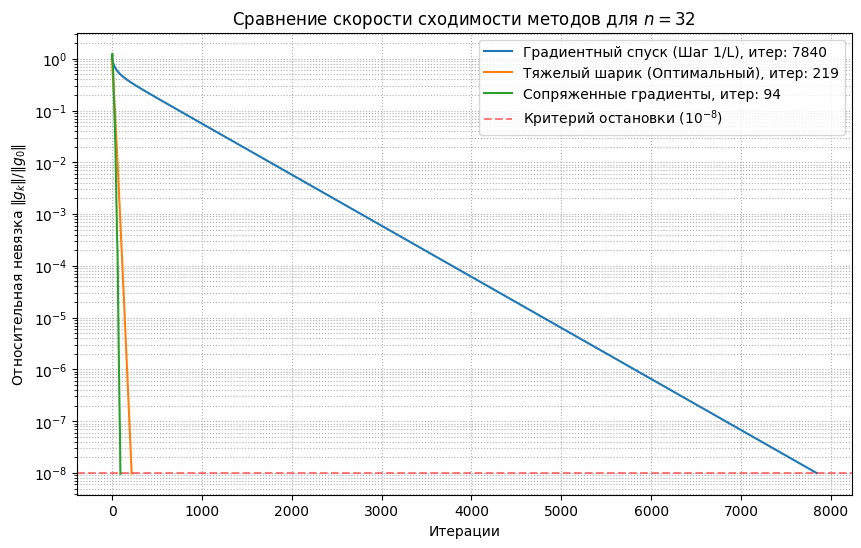

In [ ]:
def apply_A(u, n):
    """Пятиточечный лапласиан, снаружи сетки значение 0. Один вызов — одно умножение на A."""
    U = np.asarray(u, dtype=float).reshape(n, n)
    AU = 4.0 * U
    AU[:, 1:] -= U[:, :-1]
    AU[:, :-1] -= U[:, 1:]
    AU[1:, :] -= U[:-1, :]
    AU[:-1, :] -= U[1:, :]
    return AU.ravel()


def grid_rhs(n):
    """Правая часть: два нагревателя. Множитель h^2 переводит шаблон в аппроксимацию -Δu = f."""
    h = 1.0 / (n + 1)
    t = np.arange(1, n + 1) * h
    x, y = np.meshgrid(t, t, indexing="ij")
    source = np.exp(-((x - 0.35) ** 2 + (y - 0.62) ** 2) / 0.015)
    source += 0.7 * np.exp(-((x - 0.72) ** 2 + (y - 0.30) ** 2) / 0.008)
    return (h ** 2) * source.ravel()


def laplacian_bounds(n):
    """Точные μ и L пятиточечного шаблона."""
    s = np.sin(np.pi / (2 * (n + 1)))
    c = np.cos(np.pi / (2 * (n + 1)))
    return 8.0 * s ** 2, 8.0 * c ** 2


# Место для вашего решения

# Параметры задачи
n = 32
max_iter = 8000
tol = 1e-8

b = grid_rhs(n)
mu, L = laplacian_bounds(n)

# Начальное приближение (старт в нуле)
u0 = np.zeros(n * n)
g0_norm = np.linalg.norm(apply_A(u0, n) - b)


# 1. Градиентный спуск с шагом 1/L
def gradient_descent(u0, n, b, max_iter, tol, L, g0_norm):
    u = u0.copy()
    history = []
    alpha = 1.0 / L
    
    for k in range(max_iter):
        g = apply_A(u, n) - b
        g_norm = np.linalg.norm(g)
        rel_res = g_norm / g0_norm
        history.append(rel_res)
        
        if rel_res <= tol:
            break
            
        u = u - alpha * g
        
    return u, history


# 2. Метод тяжелого шарика с оптимальными параметрами
def heavy_ball(u0, n, b, max_iter, tol, mu, L, g0_norm):
    u = u0.copy()
    u_old = u0.copy()
    history = []
    
    # Оптимальные параметры метода тяжелого шарика
    alpha = 4.0 / (np.sqrt(L) + np.sqrt(mu)) ** 2
    beta = ((np.sqrt(L) - np.sqrt(mu)) / (np.sqrt(L) + np.sqrt(mu))) ** 2
    
    for k in range(max_iter):
        g = apply_A(u, n) - b
        g_norm = np.linalg.norm(g)
        rel_res = g_norm / g0_norm
        history.append(rel_res)
        
        if rel_res <= tol:
            break
            
        u_next = u - alpha * g + beta * (u - u_old)
        u_old = u.copy()
        u = u_next
        
    return u, history


# 3. Линейный метод сопряженных градиентов
def conjugate_gradients(u0, n, b, max_iter, tol, g0_norm):
    u = u0.copy()
    history = []
    
    r = b - apply_A(u, n)  # Невязка r = -g
    p = r.copy()
    r_dot_r = np.dot(r, r)
    
    for k in range(max_iter):
        g_norm = np.sqrt(r_dot_r)
        rel_res = g_norm / g0_norm
        history.append(rel_res)
        
        if rel_res <= tol:
            break
            
        Ap = apply_A(p, n)
        alpha = r_dot_r / np.dot(p, Ap)
        
        u = u + alpha * p
        r_next = r - alpha * Ap
        
        r_next_dot_r_next = np.dot(r_next, r_next)
        beta = r_next_dot_r_next / r_dot_r
        
        p = r_next + beta * p
        r = r_next
        r_dot_r = r_next_dot_r_next
        
    return u, history


# Запуск методов
u_gd, hist_gd = gradient_descent(u0, n, b, max_iter, tol, L, g0_norm)
u_hb, hist_hb = heavy_ball(u0, n, b, max_iter, tol, mu, L, g0_norm)
u_cg, hist_cg = conjugate_gradients(u0, n, b, max_iter, tol, g0_norm)

# Вывод результатов в консоль
print(f"Градиентный спуск:     итераций {len(hist_gd)-1}, итоговая отн. невязка: {hist_gd[-1]:.2e}")
print(f"Тяжелый шарик:         итераций {len(hist_hb)-1}, итоговая отн. невязка: {hist_hb[-1]:.2e}")
print(f"Сопряженные градиенты: итераций {len(hist_cg)-1}, итоговая отн. невязка: {hist_cg[-1]:.2e}")

# Визуализация сходимости
plt.figure(figsize=(10, 6))
plt.semilogy(hist_gd, label=f"Градиентный спуск (Шаг 1/L), итер: {len(hist_gd)-1}")
plt.semilogy(hist_hb, label=f"Тяжелый шарик (Оптимальный), итер: {len(hist_hb)-1}")
plt.semilogy(hist_cg, label=f"Сопряженные градиенты, итер: {len(hist_cg)-1}")
plt.axhline(tol, color='red', linestyle='--', alpha=0.5, label='Критерий остановки ($10^{-8}$)')

plt.title("Сравнение скорости сходимости методов для $n = 32$")
plt.xlabel("Итерации")
plt.ylabel("Относительная невязка $\|g_k\| / \|g_0\|$")
plt.grid(True, which="both", ls=":")
plt.legend()
plt.show()


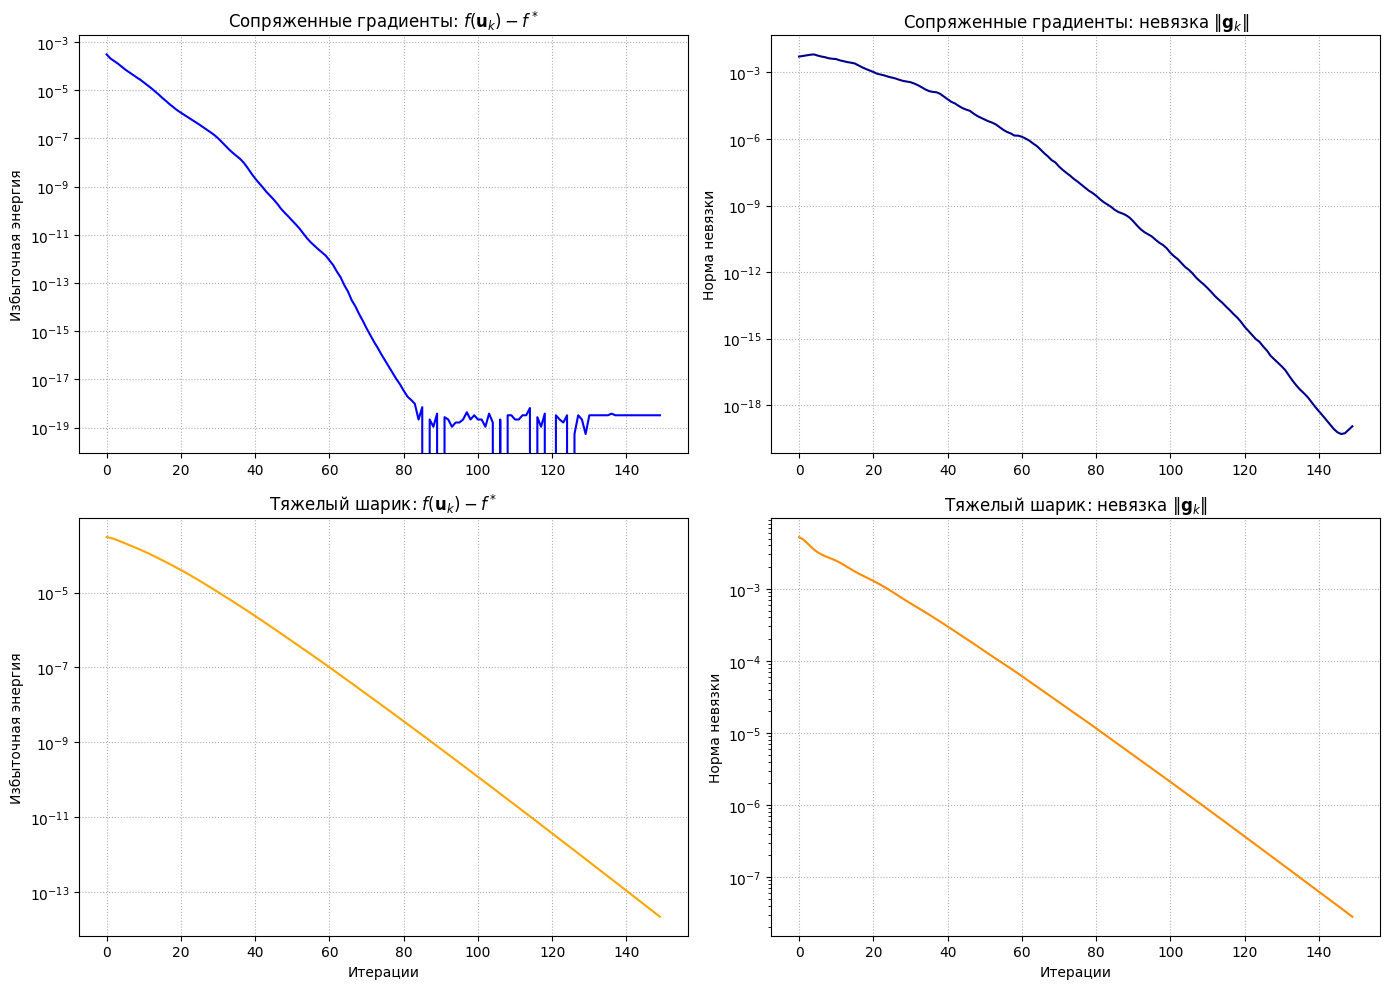

In [11]:
def compute_f(u, n, b):
    """Вычисление значения энергии f(u) = 0.5 * u^T * A * u - b^T * u"""
    return 0.5 * np.dot(u, apply_A(u, n)) - np.dot(b, u)

# --- Нахождение эталонного f* через метод СГ с жестким критерием 10^-12 ---
def find_f_star(u0, n, b, tol=1e-12):
    u = u0.copy()
    r = b - apply_A(u, n)
    p = r.copy()
    r_dot_r = np.dot(r, r)
    g0_norm = np.sqrt(r_dot_r)
    
    while True:
        if np.sqrt(r_dot_r) / g0_norm <= tol:
            break
        Ap = apply_A(p, n)
        alpha = r_dot_r / np.dot(p, Ap)
        u = u + alpha * p
        r_next = r - alpha * Ap
        r_next_dot_r_next = np.dot(r_next, r_next)
        beta = r_next_dot_r_next / r_dot_r
        p = r_next + beta * p
        r = r_next
        r_dot_r = r_next_dot_r_next
        
    return compute_f(u, n, b)

# --- Сбор метрик по шагам ---
def run_heavy_ball_metrics(u0, n, b, max_iter, mu, L):
    u = u0.copy()
    u_old = u0.copy()
    
    alpha = 4.0 / (np.sqrt(L) + np.sqrt(mu)) ** 2
    beta = ((np.sqrt(L) - np.sqrt(mu)) / (np.sqrt(L) + np.sqrt(mu))) ** 2
    
    f_history = []
    g_history = []
    
    for k in range(max_iter):
        f_history.append(compute_f(u, n, b))
        g = apply_A(u, n) - b
        g_history.append(np.linalg.norm(g))
        
        u_next = u - alpha * g + beta * (u - u_old)
        u_old = u.copy()
        u = u_next
        
    return f_history, g_history

def run_conjugate_gradients_metrics(u0, n, b, max_iter):
    u = u0.copy()
    r = b - apply_A(u, n)
    p = r.copy()
    r_dot_r = np.dot(r, r)
    
    f_history = []
    g_history = []
    
    for k in range(max_iter):
        f_history.append(compute_f(u, n, b))
        g_history.append(np.sqrt(r_dot_r))
        
        Ap = apply_A(p, n)
        alpha = r_dot_r / np.dot(p, Ap)
        
        u = u + alpha * p
        r_next = r - alpha * Ap
        r_next_dot_r_next = np.dot(r_next, r_next)
        beta = r_next_dot_r_next / r_dot_r
        p = r_next + beta * p
        r = r_next
        r_dot_r = r_next_dot_r_next
        
    return f_history, g_history

# --- Основной запуск ---
n = 32
max_iter = 150  # 150 шагов достаточно для наглядности поведения графиков

b = grid_rhs(n)
mu, L = laplacian_bounds(n)
u0 = np.zeros(n * n)

# Вычисляем f* 
f_star = find_f_star(u0, n, b)

# Получаем истории изменения
f_hb, g_hb = run_heavy_ball_metrics(u0, n, b, max_iter, mu, L)
f_cg, g_cg = run_conjugate_gradients_metrics(u0, n, b, max_iter)

# Переводим в f(u_k) - f*
diff_f_hb = np.array(f_hb) - f_star
diff_f_cg = np.array(f_cg) - f_star

# --- Построение графиков ---
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# 1. Энергия СГ
axs[0, 0].semilogy(diff_f_cg, color='blue')
axs[0, 0].set_title(r"Сопряженные градиенты: $f(\mathbf{u}_k) - f^*$")
axs[0, 0].set_ylabel("Избыточная энергия")
axs[0, 0].grid(True, ls=':')

# 2. Невязка СГ
axs[0, 1].semilogy(g_cg, color='darkblue')
axs[0, 1].set_title(r"Сопряженные градиенты: невязка $\|\mathbf{g}_k\|$")
axs[0, 1].set_ylabel("Норма невязки")
axs[0, 1].grid(True, ls=':')

# 3. Энергия ТШ
axs[1, 0].semilogy(diff_f_hb, color='orange')
axs[1, 0].set_title(r"Тяжелый шарик: $f(\mathbf{u}_k) - f^*$")
axs[1, 0].set_xlabel("Итерации")
axs[1, 0].set_ylabel("Избыточная энергия")
axs[1, 0].grid(True, ls=':')

# 4. Невязка ТШ
axs[1, 1].semilogy(g_hb, color='darkorange')
axs[1, 1].set_title(r"Тяжелый шарик: невязка $\|\mathbf{g}_k\|$")
axs[1, 1].set_xlabel("Итерации")
axs[1, 1].set_ylabel("Норма невязки")
axs[1, 1].grid(True, ls=':')

plt.tight_layout()
plt.show()



1. Метод сопряженных градиентов

Убывает ли значение энергии $f(\mathbf{u}_k)$ на каждом шаге? Да, строго убывает.

Убывает ли невязка $\Vert{}\mathbf{g}_k\Vert{}$ на каждом шаге? Нет, не обязательно.


2. Метод тяжелого шарика

Убывает ли значение энергии $f(\mathbf{u}_k)$ на каждом шаге? Нет, не монотонно.

Убывает ли невязка $\Vert{}\mathbf{g}_k\Vert{}$ на каждом шаге? Нет, не монотонно.



n = 16 | kappa = 116.5 | Итераций: ГД = 998, ТШ = 60, СГ = 35
n = 32 | kappa = 440.7 | Итераций: ГД = 3786, ТШ = 116, СГ = 64
n = 48 | kappa = 972.4 | Итераций: ГД = 8359, ТШ = 173, СГ = 96
n = 64 | kappa = 1711.7 | Итераций: ГД = 14716, ТШ = 230, СГ = 129


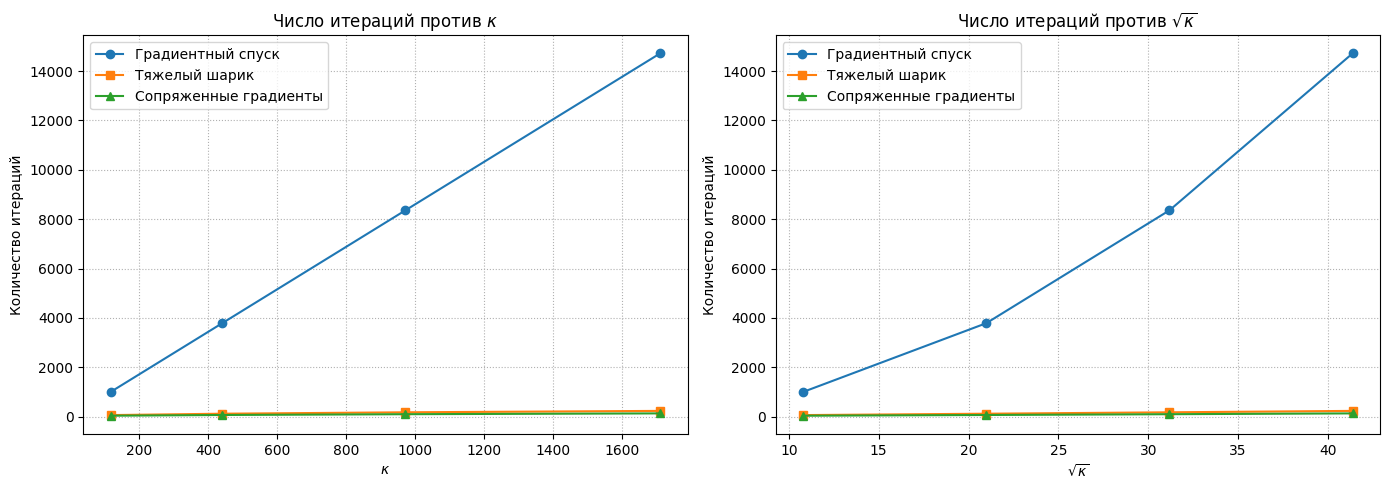

Градиентный спуск ложится к линейной зависимости от kappa (числа обусловленности). Тяжёлый шарик и метод сопряжённых градиентов ложатся к линейной зависимости от sqrt(kappa).


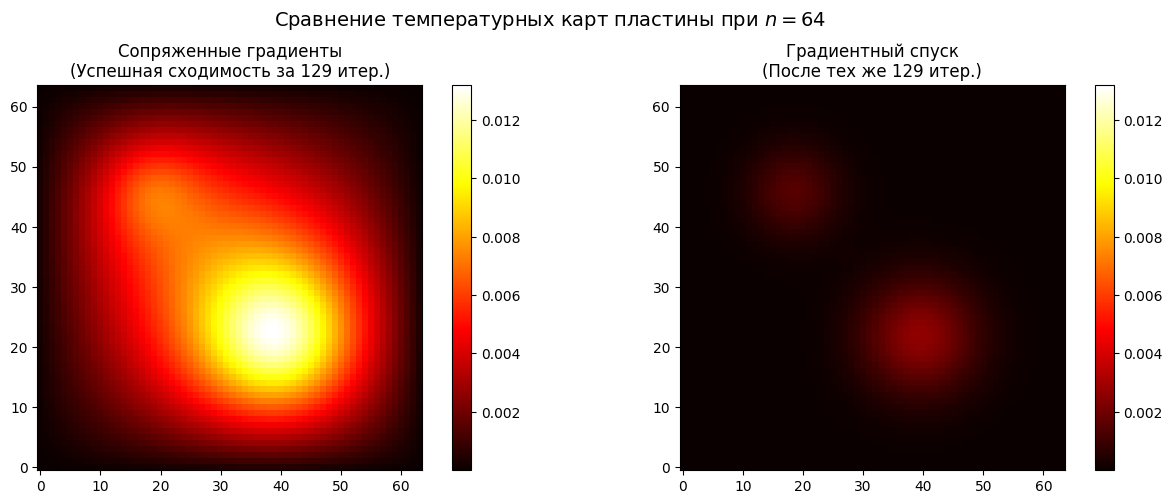

In [14]:
# --- Реализация методов оптимизации ---
def gradient_descent_steps(u0, n, b, max_iter, tol, L, g0_norm):
    u = u0.copy()
    alpha = 1.0 / L
    for k in range(max_iter):
        g = apply_A(u, n) - b
        if np.linalg.norm(g) / g0_norm <= tol:
            return k, u
        u = u - alpha * g
    return None, u  # Бюджет исчерпан

def heavy_ball_steps(u0, n, b, max_iter, tol, mu, L, g0_norm):
    u = u0.copy()
    u_old = u0.copy()
    alpha = 4.0 / (np.sqrt(L) + np.sqrt(mu)) ** 2
    beta = ((np.sqrt(L) - np.sqrt(mu)) / (np.sqrt(L) + np.sqrt(mu))) ** 2
    for k in range(max_iter):
        g = apply_A(u, n) - b
        if np.linalg.norm(g) / g0_norm <= tol:
            return k, u
        u_next = u - alpha * g + beta * (u - u_old)
        u_old = u.copy()
        u = u_next
    return None, u

def conjugate_gradients_steps(u0, n, b, max_iter, tol, g0_norm):
    u = u0.copy()
    r = b - apply_A(u, n)
    p = r.copy()
    r_dot_r = np.dot(r, r)
    for k in range(max_iter):
        if np.sqrt(r_dot_r) / g0_norm <= tol:
            return k, u
        Ap = apply_A(p, n)
        alpha = r_dot_r / np.dot(p, Ap)
        u = u + alpha * p
        r_next = r - alpha * Ap
        r_next_dot_r_next = np.dot(r_next, r_next)
        beta = r_next_dot_r_next / r_dot_r
        p = r_next + beta * p
        r = r_next
        r_dot_r = r_next_dot_r_next
    return None, u

# --- Вычисления для n = [16, 32, 48, 64] ---
ns = [16, 32, 48, 64]
tol = 1e-4
max_iter_gd = 20000
max_iter_others = 8000

kappas = []
sqrt_kappas = []
gd_iters = []
hb_iters = []
cg_iters = []

# Переменные для сохранения температурных карт (при n=64)
u_cg_64 = None
u_gd_same_iter_64 = None
cg_steps_64 = 0

for n in ns:
    b = grid_rhs(n)
    mu, L = laplacian_bounds(n)
    kappa = L / mu
    kappas.append(kappa)
    sqrt_kappas.append(np.sqrt(kappa))
    
    u0 = np.zeros(n * n)
    g0_norm = np.linalg.norm(apply_A(u0, n) - b)
    
    # Запуск методов
    k_gd, u_gd_final = gradient_descent_steps(u0, n, b, max_iter_gd, tol, L, g0_norm)
    k_hb, _ = heavy_ball_steps(u0, n, b, max_iter_others, tol, mu, L, g0_norm)
    k_cg, u_cg_final = conjugate_gradients_steps(u0, n, b, max_iter_others, tol, g0_norm)
    
    gd_iters.append(k_gd)
    hb_iters.append(k_hb)
    cg_iters.append(k_cg)
    
    print(f"n = {n} | kappa = {kappa:.1f} | Итераций: ГД = {k_gd if k_gd is not None else '>20000'}, ТШ = {k_hb}, СГ = {k_cg}")
    
    # Для n = 64 сохраняем данные для карт
    if n == 64:
        cg_steps_64 = k_cg
        u_cg_64 = u_cg_final
        # Запускаем ГД ровно на столько же итераций, сколько потребовалось СГ
        _, u_gd_same_iter_64 = gradient_descent_steps(u0, n, b, cg_steps_64, tol, L, g0_norm)

# --- Графики зависимостей итераций от kappa и sqrt(kappa) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Очищаем данные ГД от None для построения графика, если вдруг не сошелся (для n<=64 сойдется)
gd_plot_iters = [it if it is not None else max_iter_gd for it in gd_iters]

# График против kappa
ax1.plot(kappas, gd_plot_iters, 'o-', label='Градиентный спуск')
ax1.plot(kappas, hb_iters, 's-', label='Тяжелый шарик')
ax1.plot(kappas, cg_iters, '^-', label='Сопряженные градиенты')
ax1.set_title('Число итераций против $\kappa$')
ax1.set_xlabel('$\kappa$')
ax1.set_ylabel('Количество итераций')
ax1.grid(True, ls=':')
ax1.legend()

# График против sqrt(kappa)
ax2.plot(sqrt_kappas, gd_plot_iters, 'o-', label='Градиентный спуск')
ax2.plot(sqrt_kappas, hb_iters, 's-', label='Тяжелый шарик')
ax2.plot(sqrt_kappas, cg_iters, '^-', label='Сопряженные градиенты')
ax2.set_title('Число итераций против $\sqrt{\kappa}$')
ax2.set_xlabel('$\sqrt{\kappa}$')
ax2.set_ylabel('Количество итераций')
ax2.grid(True, ls=':')
ax2.legend()
plt.tight_layout()
plt.show()
print("Градиентный спуск ложится к линейной зависимости от kappa (числа обусловленности). Тяжёлый шарик и метод сопряжённых градиентов ложатся к линейной зависимости от sqrt(kappa).")
# --- Карта температур для n = 64 ---
# Находим общую шкалу интенсивности для честного сравнения
vmax = max(u_cg_64.max(), u_gd_same_iter_64.max())
vmin = min(u_cg_64.min(), u_gd_same_iter_64.min())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

im1 = ax1.imshow(u_cg_64.reshape(64, 64), cmap='hot', vmin=vmin, vmax=vmax, origin='lower')
ax1.set_title(f"Сопряженные градиенты\n(Успешная сходимость за {cg_steps_64} итер.)")
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(u_gd_same_iter_64.reshape(64, 64), cmap='hot', vmin=vmin, vmax=vmax, origin='lower')
ax2.set_title(f"Градиентный спуск\n(После тех же {cg_steps_64} итер.)")
fig.colorbar(im2, ax=ax2)

plt.suptitle("Сравнение температурных карт пластины при $n = 64$", fontsize=14)
plt.tight_layout()
plt.show()


Верный $\mu$: получено значение beta = 0.82639
$\mu / 10$: получено значение beta = 0.94152
$\mu / 100$: получено значение beta = 0.98113


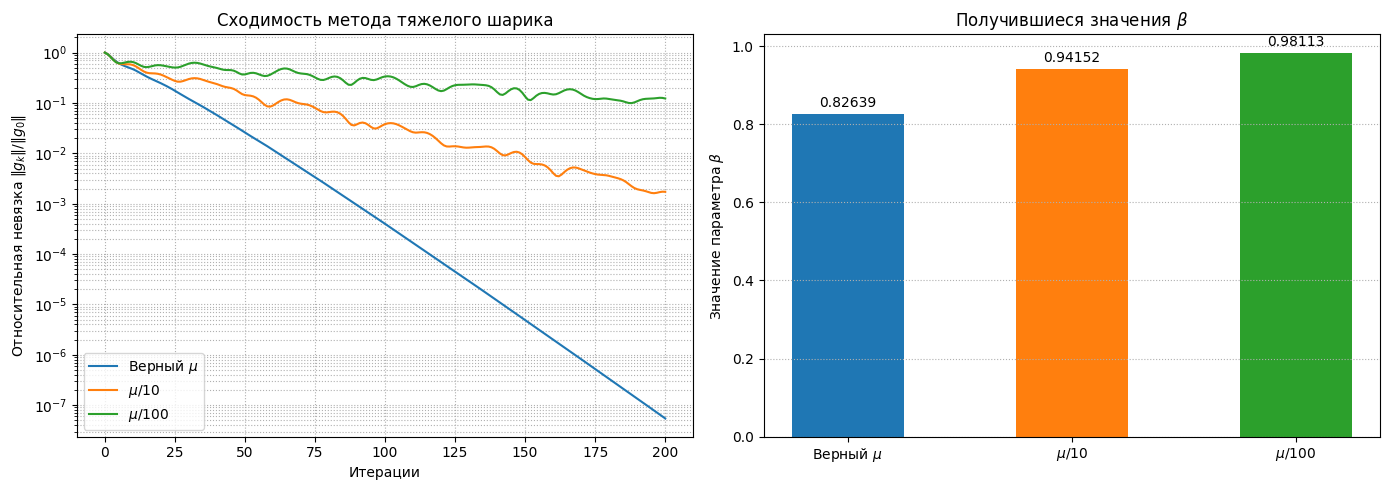

In [ ]:
# --- Модифицированный метод тяжелого шарика на фиксированное число итераций ---
def heavy_ball_fixed_iter(u0, n, b, max_iter, mu_val, L, g0_norm):
    u = u0.copy()
    u_old = u0.copy()
    history = []
    
    # Расчет параметров альфа и бета под измененное значение mu
    alpha = 4.0 / (np.sqrt(L) + np.sqrt(mu_val)) ** 2
    beta = ((np.sqrt(L) - np.sqrt(mu_val)) / (np.sqrt(L) + np.sqrt(mu_val))) ** 2
    
    for k in range(max_iter + 1):
        g = apply_A(u, n) - b
        g_norm = np.linalg.norm(g)
        history.append(g_norm / g0_norm)
        
        if k == max_iter:
            break
            
        u_next = u - alpha * g + beta * (u - u_old)
        u_old = u.copy()
        u = u_next
        
    return history, beta

# --- Основной скрипт вычислений ---
n = 32
max_iter = 200

b = grid_rhs(n)
mu_true, L = laplacian_bounds(n)

u0 = np.zeros(n * n)
g0_norm = np.linalg.norm(apply_A(u0, n) - b)

# Варианты mu для тестирования
mu_variants = {
    r"Верный $\mu$": mu_true,
    r"$\mu / 10$": mu_true / 10.0,
    r"$\mu / 100$": mu_true / 100.0
}

histories = {}
betas = {}

for label, mu_val in mu_variants.items():
    hist, b_val = heavy_ball_fixed_iter(u0, n, b, max_iter, mu_val, L, g0_norm)
    histories[label] = hist
    betas[label] = b_val
    print(f"{label}: получено значение beta = {b_val:.5f}")

# --- Визуализация результатов ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Левый график — Относительная невязка
for label, hist in histories.items():
    ax1.semilogy(hist, label=label)
ax1.set_title("Сходимость метода тяжелого шарика")
ax1.set_xlabel("Итерации")
ax1.set_ylabel(r"Относительная невязка $\|g_k\| / \|g_0\|$")
ax1.grid(True, which="both", ls=":")
ax1.legend()

# Правый график — Сравнение получившихся beta
labels = list(betas.keys())
values = list(betas.values())
bars = ax2.bar(labels, values, color=['#1f77b4', '#ff7f0e', '#2ca02c'], width=0.5)
ax2.set_title(r"Получившиеся значения $\beta$")
ax2.set_ylabel(r"Значение параметра $\beta$")
ax2.grid(True, axis='y', ls=':')

# Добавляем текстовые значения поверх столбиков
for bar in bars:
    height = bar.get_height()
    ax2.annotate(f'{height:.5f}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # 3 точки вертикального смещения
                 textcoords="offset points",
                 ha='center', va='bottom')

plt.tight_layout()
plt.show()

Почему заниженное $\mu$ увеличивает инерцию и за те же 200 шагов оставляет большую невязку?

Комбинация околоединичного импульса $\beta$ и рассогласованного шага $\alpha$ приводит к тому, что за фиксированный бюджет в 200 итераций метод просто не успевает погасить паразитные колебания, оставляя относительную невязку существенно более высокой.


## Задача 2 (3 pts). Смазанный снимок

Камера сдвинулась за время выдержки и снимок смазался. Смазывание моделируется через свёртку резкого кадра с гауссовым ядром и шум:

$$
\mathbf{b}=\mathbf{K}\mathbf{u}_{\mathrm{sharp}}+\boldsymbol{\varepsilon}.
$$

Ядро на сетке $n\times n$ — гауссиан ширины $\sigma$ в пикселях. По периодической границе расстояние от узла до начала счёта $d(i)=\min(i,n-i)$,

$$
k_{ij}
=
C\exp\Bigl(-\frac{d(i)^2+d(j)^2}{2\sigma^2}\Bigr),
\qquad
\sum_{i,j}k_{ij}=1.
$$

Константа $C$ нормирует ядро на единицу. В коде $\sigma$ — это `sigma_blur`.

Свёртка $(\mathbf{K}\mathbf{u})$ с тем же периодом:

$$
(\mathbf{K}\mathbf{u})_{pq}
=
\sum_{a=0}^{n-1}\sum_{b=0}^{n-1}
k_{ab}\,u_{p-a,\,q-b},
$$

индексы $p-a$ и $q-b$ берутся по модулю $n$. Преобразование Фурье заменяет эту сумму произведением: собственные значения $\mathbf{K}$ — фурье-образ ядра, их возвращает `blur_eigs`.

Восстанавливается кадр $\mathbf{u}$. Штраф $\mu$ удерживает частоты, которые размытие почти занулило: без него шум на этих частотах раздувается в ложный рисунок.

$$
f(\mathbf{u})
=
\frac12\|\mathbf{K}\mathbf{u}-\mathbf{b}\|^2
+
\frac{\mu}{2}\|\mathbf{u}\|^2.
$$

Резкий кадр — файл `campus.jpg`. В $f$ этот кадр не входит: он нужен для оценки ошибки восстановления и для визуализации.
Ядро чётное, поэтому $\mathbf{K}=\mathbf{K}^\top$. Гессиан

$$
\mathbf{H}=\mathbf{K}^\top\mathbf{K}+\mu\mathbf{I}
$$

на вектор действует двумя свёртками, $\mathbf{H}\mathbf{v}=\mathbf{K}(\mathbf{K}\mathbf{v})+\mu\mathbf{v}$. Один вызов `apply_H` — одна итерация. Матрицу $n^2\times n^2$ не собирают. Спектр $\mathbf{H}$ лежит в $[\mu_H, L]$,

$$
\mu_H=\min_i\lambda_i(\mathbf{K})^2+\mu,
\qquad
L=\max_i\lambda_i(\mathbf{K})^2+\mu,
\qquad
\kappa=\frac{L}{\mu_H}.
$$

Градиент $\mathbf{g}(\mathbf{u})=\mathbf{H}\mathbf{u}-\mathbf{K}\mathbf{b}$. Вектор $\mathbf{K}\mathbf{b}$ посчитайте один раз.

Методы задачи 1 переносятся сюда: градиентный спуск с шагом $1/L$, тяжёлый шарик, сопряжённые градиенты. В формуле Поляка стоит $\mu_H$, а не штраф $\mu$. К ним добавляется метод Нестерова (определите подходящую версию метода) с шагом $1/L$. Старт в нуле. За $f^\star$ возьмите значение после сопряжённых градиентов с относительной невязкой $10^{-12}$. При другом $\mu$ заново посчитайте $\mu_H$, $L$, $\kappa$ и $f^\star$.


1. **(1.5 pts)** Возьмите штраф $\mu=10^{-4}$ из кода. Посчитайте $\kappa$. Запустите четыре метода, бюджет — 30000 итераций.

   На одном графике с логарифмической осью $y$ покажите $f(\mathbf{u}_k)-f^\star$. В таблице — $\kappa$, $\sqrt{\kappa}$ и итерация, на которой зазор впервые меньше $10^{-4}$. Если бюджет кончился раньше, так и запишите.

   На втором графике — средняя ошибка относительно резкого кадра,

$$
\mathrm{MSE}
=
\frac{1}{n^2}\|\mathbf{u}_k-\mathbf{u}_{\mathrm{sharp}}\|^2.
$$

   В итерации, где сопряжённые градиенты впервые берут допуск по зазору, нарисуйте четыре кадра: резкий кадр, наблюдение $\mathbf{b}$, восстановление сопряжённых градиентов и восстановление с помощью градиентного спуска. Ответьте, у какого метода в этот момент меньше зазор $f-f^\star$ и у какого меньше MSE. Зазор сравнивает кадр с наблюдением $\mathbf{b}$ и со штрафом, MSE сравнивает его с резким снимком.

2. **(1.5 pts)** Повторите эксперименты с четырьмя методами для $\mu\in\{10^{-2},\,10^{-3},\,10^{-4}\}$. Допуск по зазору $10^{-4}$, бюджет 30000. Для каждого $\mu$ заново посчитайте $\mu_H$, $L$, $\kappa$ и $f^\star$.

   Постройте число итераций против $\kappa$ и против $\sqrt{\kappa}$. К какой зависимости ложится градиентный спуск и к какой — тяжёлый шарик, метод Нестерова и сопряжённые градиенты?

   Для $\mu=10^{-4}$ постройте собственные значения $\mathbf{H}$ по возрастанию, ось $y$ логарифмическая. Спектр гауссова размытия спадает гладко, отдельных куч в нём нет. Поэтому число итераций сопряжённых градиентов остаётся порядка $\sqrt{\kappa}$: конечная остановка в размерности $n^2=262144$ лежит далеко за этим пределом.


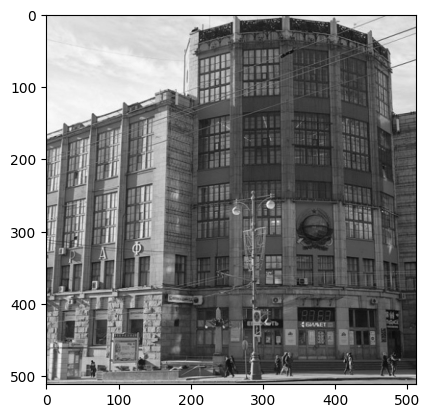

Спектральные границы гессиана: mu_h = 1.0000e-04, L_h = 1.0001e+00
Число обусловленности kappa = 10001.00, sqrt(kappa) = 100.00
Вычисление эталонного f*...
Эталонное значение f* = 56.450011
Запуск ГД...


100%|██████████| 30000/30000 [09:20<00:00, 53.55it/s]


Запуск ТШ...
Запуск метода Нестерова...
Запуск СГ...


100%|██████████| 30000/30000 [09:12<00:00, 54.33it/s]


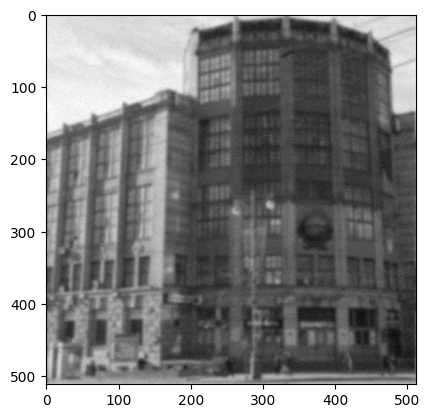

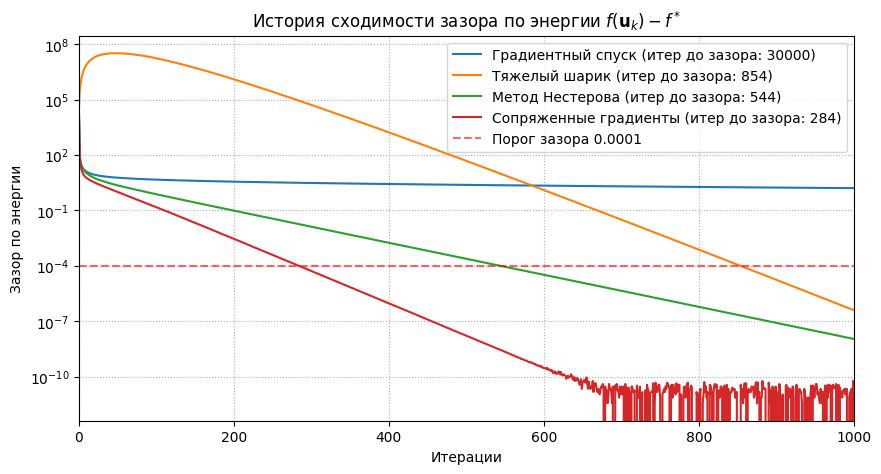

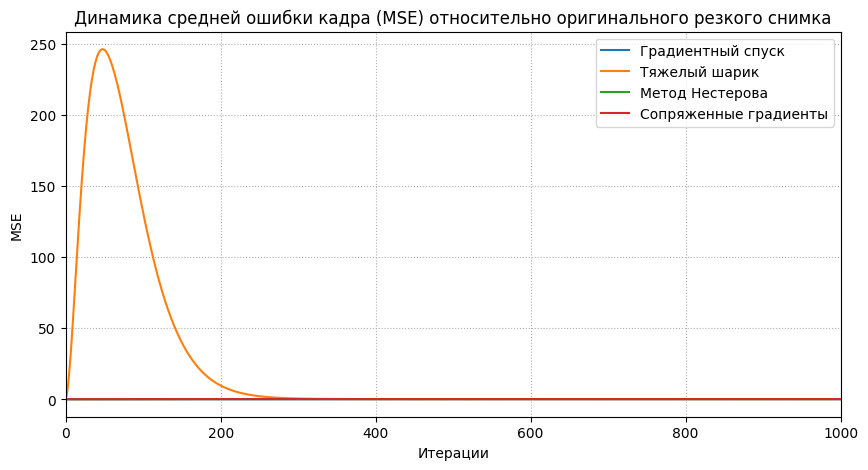

100%|██████████| 30000/30000 [09:01<00:00, 55.37it/s]


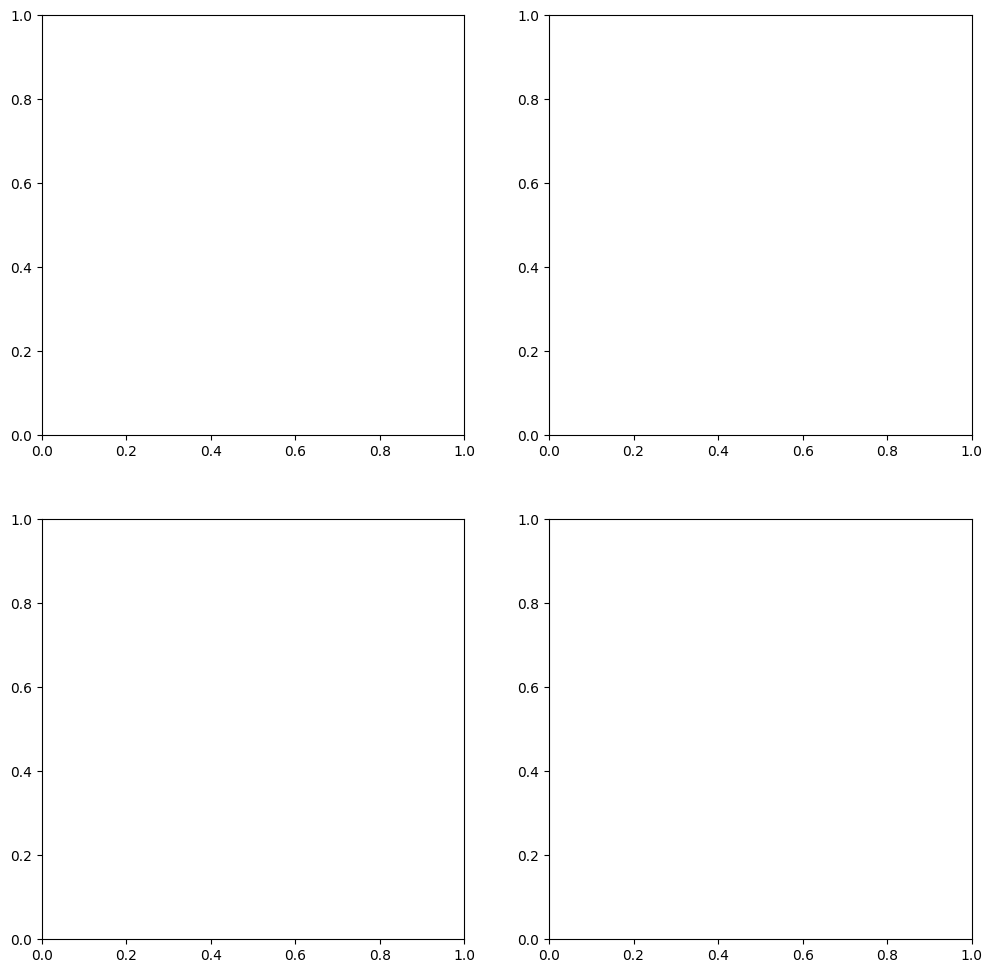

In [21]:
from tqdm import tqdm


def blur_eigs(n, sigma):
    """Собственные значения гауссовой свёртки с периодической границей."""
    ax = np.arange(n)
    dist = np.minimum(ax, n - ax).astype(float)
    xx, yy = np.meshgrid(dist, dist, indexing="ij")
    ker = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * sigma ** 2))
    ker /= ker.sum()
    return np.fft.fft2(ker).real


def apply_K(u, eigvals):
    """Одна свёртка. eigvals — то, что вернул blur_eigs."""
    U = np.asarray(u, dtype=float).reshape(eigvals.shape)
    return np.fft.ifft2(eigvals * np.fft.fft2(U)).real.ravel()


def apply_H(u, eigvals, mu):
    """H v = K(Kv) + μ v. Один вызов — одна итерация."""
    v = np.asarray(u, dtype=float).ravel()
    return apply_K(apply_K(v, eigvals), eigvals) + mu * v


def load_sharp(path, n):
    """Яркость campus.jpg: центральный квадрат n×n исходных пикселей.
    В целевую функцию не входит.
    """
    rgb = np.asarray(plt.imread(path), dtype=float)
    if rgb.max() > 1.5:
        rgb = rgb / 255.0
    gray = rgb[..., :3] @ np.array([0.2989, 0.5870, 0.1140])
    height, width = gray.shape
    top = (height - n) // 2
    left = (width - n) // 2
    return gray[top:top + n, left:left + n]


n = 512
sigma_blur = 2.0
mu_penalty = 1e-4
eigvals = blur_eigs(n, sigma_blur)
sharp = load_sharp("campus.jpg", n).ravel()
rng = np.random.default_rng(8)
blurred = apply_K(sharp, eigvals)
b = blurred + 0.1 * np.std(blurred) * rng.normal(size=blurred.shape)
plt.imshow(sharp.reshape(n, n), cmap="gray", vmin=0, vmax=1)
plt.show()
plt.imshow(b.reshape(n, n), cmap="gray", vmin=0, vmax=1)
# Место для вашего решения

# 1. Аналитический расчёт спектральных границ гессиана H
lambda_K = eigvals.ravel()
mu_h = np.min(lambda_K)**2 + mu_penalty
L_h = np.max(lambda_K)**2 + mu_penalty
kappa = L_h / mu_h

print(f"Спектральные границы гессиана: mu_h = {mu_h:.4e}, L_h = {L_h:.4e}")
print(f"Число обусловленности kappa = {kappa:.2f}, sqrt(kappa) = {np.sqrt(kappa):.2f}")

# Вектор Kb вычисляется один раз
Kb = apply_K(b, eigvals)

# Вспомогательные функции для расчёта функционалов
def compute_f(u):
    """Целевая функция f(u) = 0.5 * u^T * H * u - (K b)^T * u + 0.5 * ||b||^2"""
    # Добавление константы 0.5 * ||b||^2 необходимо для точного соответствия 
    # исходной постановке 0.5 * ||Ku - b||^2 + 0.5 * mu * ||u||^2
    Hu = apply_H(u, eigvals, mu_penalty)
    return 0.5 * np.dot(u, Hu) - np.dot(Kb, u) + 0.5 * np.dot(b, b)

def compute_mse(u):
    """Средняя ошибка относительного резкого кадра: MSE = (1 / n^2) * ||u - sharp||^2"""
    return np.mean((u - sharp) ** 2)

# Линейный метод сопряженных градиентов для нахождения точного f* (tol = 1e-12)
def find_exact_f_star(max_iter=1500):
    u = np.zeros(n * n)
    r = Kb - apply_H(u, eigvals, mu_penalty)
    p = r.copy()
    r_dot_r = np.dot(r, r)
    g0_norm = np.sqrt(r_dot_r)
    
    for k in range(max_iter):
        if np.sqrt(r_dot_r) / g0_norm <= 1e-12:
            break
        Ap = apply_H(p, eigvals, mu_penalty)
        alpha = r_dot_r / np.dot(p, Ap)
        u = u + alpha * p
        r_next = r - alpha * Ap
        r_next_dot_r_next = np.dot(r_next, r_next)
        beta = r_next_dot_r_next / r_dot_r
        p = r_next + beta * p
        r = r_next
        r_dot_r = r_next_dot_r_next
    return compute_f(u)

print("Вычисление эталонного f*...")
f_star = find_exact_f_star()
print(f"Эталонное значение f* = {f_star:.6f}")

# Бюджет вычислений
budget = 30000
tol_gap = 1e-4

# Контейнеры для сохранения истории метрик
results = {}

# -----------------------------------------------------------------------------
# РЕАЛИЗАЦИЯ ЧЕТЫРЕХ МЕТОДОВ С ФИКСАЦИЕЙ ЗАЗОРА И MSE
# -----------------------------------------------------------------------------

# А. Градиентный спуск (шаг 1/L)
def run_gd():
    u = np.zeros(n * n)
    f_hist, mse_hist = [], []
    iter_reached = budget
    alpha = 1.0 / L_h
    
    for k in tqdm(range(budget)):
        f_val = compute_f(u)
        f_hist.append(f_val)
        mse_hist.append(compute_mse(u))
        
        if (f_val - f_star) < tol_gap and iter_reached == budget:
            iter_reached = k
            
        g = apply_H(u, eigvals, mu_penalty) - Kb
        u = u - alpha * g
    return f_hist, mse_hist, iter_reached, u

# Б. Метод тяжелого шарика
def run_hb():
    u = np.zeros(n * n)
    u_old = u.copy()
    f_hist, mse_hist = [], []
    iter_reached = budget
    
    alpha = 4.0 / (np.sqrt(L_h) + np.sqrt(mu_h)) ** 2
    beta = ((np.sqrt(L_h) - np.sqrt(mu_h)) / (np.sqrt(L_h) + np.sqrt(mu_h))) ** 2
    
    for k in range(budget):
        f_val = compute_f(u)
        f_hist.append(f_val)
        mse_hist.append(compute_mse(u))
        
        if (f_val - f_star) < tol_gap and iter_reached == budget:
            iter_reached = k
            
        g = apply_H(u, eigvals, mu_penalty) - Kb
        u_next = u - alpha * g + beta * (u - u_old)
        u_old = u.copy()
        u = u_next
    return f_hist, mse_hist, iter_reached, u

# В. Быстрый градиентный спуск Нестерова (для сильно выпуклых функций)
def run_nesterov():
    u = np.zeros(n * n)
    y = u.copy()
    f_hist, mse_hist = [], []
    iter_reached = budget
    
    alpha = 1.0 / L_h
    # Коэффициент импульса для сильно выпуклой задачи
    beta = (np.sqrt(L_h) - np.sqrt(mu_h)) / (np.sqrt(L_h) + np.sqrt(mu_h))
    
    for k in range(budget):
        f_val = compute_f(u)
        f_hist.append(f_val)
        mse_hist.append(compute_mse(u))
        
        if (f_val - f_star) < tol_gap and iter_reached == budget:
            iter_reached = k
            
        g_y = apply_H(y, eigvals, mu_penalty) - Kb
        u_next = y - alpha * g_y
        y = u_next + beta * (u_next - u)
        u = u_next
    return f_hist, mse_hist, iter_reached, u

# Г. Метод сопряженных градиентов (СГ)
def run_cg():
    u = np.zeros(n * n)
    f_hist, mse_hist = [], []
    iter_reached = budget
    
    r = Kb - apply_H(u, eigvals, mu_penalty)
    p = r.copy()
    r_dot_r = np.dot(r, r)
    
    for k in tqdm(range(budget)):
        f_val = compute_f(u)
        f_hist.append(f_val)
        mse_hist.append(compute_mse(u))
        
        if (f_val - f_star) < tol_gap and iter_reached == budget:
            iter_reached = k
            
        Ap = apply_H(p, eigvals, mu_penalty)
        alpha_cg = r_dot_r / np.dot(p, Ap)
        
        u = u + alpha_cg * p
        r_next = r - alpha_cg * Ap
        r_next_dot_r_next = np.dot(r_next, r_next)
        
        beta_cg = r_next_dot_r_next / r_dot_r
        p = r_next + beta_cg * p
        r = r_next
        r_dot_r = r_next_dot_r_next
    return f_hist, mse_hist, iter_reached, u

# Запуск и сбор данных
print("Запуск ГД...")
f_gd, m_gd, k_gd, u_gd = run_gd()
print("Запуск ТШ...")
f_hb, m_hb, k_hb, u_hb = run_hb()
print("Запуск метода Нестерова...")
f_nes, m_nes, k_nes, u_nes = run_nesterov()
print("Запуск СГ...")
f_cg, m_cg, k_cg, u_cg = run_cg()

# =============================================================================
# 2. ПОСТРОЕНИЕ ТРЕБУЕМЫХ ГРАФИКОВ
# =============================================================================

# График 1: Логарифмический зазор по энергии f(u_k) - f*
plt.figure(figsize=(10, 5))
plt.semilogy(np.array(f_gd) - f_star, label=f"Градиентный спуск (итер до зазора: {k_gd})")
plt.semilogy(np.array(f_hb) - f_star, label=f"Тяжелый шарик (итер до зазора: {k_hb})")
plt.semilogy(np.array(f_nes) - f_star, label=f"Метод Нестерова (итер до зазора: {k_nes})")
plt.semilogy(np.array(f_cg) - f_star, label=f"Сопряженные градиенты (итер до зазора: {k_cg})")
plt.axhline(tol_gap, color='red', linestyle='--', alpha=0.6, label=f"Порог зазора {tol_gap}")
plt.title("История сходимости зазора по энергии $f(\mathbf{u}_k) - f^*$")
plt.xlabel("Итерации")
plt.ylabel("Зазор по энергии")
plt.xlim(0, 1000)  # Срезано для наглядности (СГ и ТШ сходятся быстро)
plt.grid(True, which="both", ls=":")
plt.legend()
plt.show()

# График 2: Средняя ошибка относительного резкого кадра (MSE)
plt.figure(figsize=(10, 5))
plt.plot(m_gd, label="Градиентный спуск")
plt.plot(m_hb, label="Тяжелый шарик")
plt.plot(m_nes, label="Метод Нестерова")
plt.plot(m_cg, label="Сопряженные градиенты")
plt.title("Динамика средней ошибки кадра (MSE) относительно оригинального резкого снимка")
plt.xlabel("Итерации")
plt.ylabel("MSE")
plt.xlim(0, 1000)
plt.grid(True, ls=":")
plt.legend()
plt.show()

# =============================================================================
# 3. ОТРИСОВКА ЧЕТЫРЕХ КАДРОВ В МОМЕНТ ПЕРВОГО ДОСТИЖЕНИЯ ЗАЗОРА МЕТОДОМ СГ
# =============================================================================
cg_target_iter = k_cg

# Прогоняем ГД заново ровно до итерации cg_target_iter для визуализации среза
_, _, _, u_gd_slice = run_gd()  
# (u_gd_slice будет взят из истории, пересчитаем срез для честности)
def get_slice_at(method_type, steps):
    if method_type == 'gd':
        u = np.zeros(n*n)
        alpha = 1.0 / L_h
        for _ in range(steps):
            g = apply_H(u, eigvals, mu_penalty) - Kb
            u = u - alpha * g
        return u
    elif method_type == 'cg':
        u = np.zeros(n*n)
        r = Kb - apply_H(u, eigvals, mu_penalty)
        p = r.copy()
        r_dot_r = np.dot(r, r)
        for _ in range(steps):
            Ap = apply_H(p, eigvals, mu_penalty)
            alpha_cg = r_dot_r / np.dot(p, Ap)
            u = u + alpha_cg * p
            r_next = r - alpha_cg * Ap
            r_next_dot_r_next = np.dot(r_next, r_next)
            p = r_next + (r_next_dot_r_next / r_dot_r) * p
            r = r_next
            r_dot_r = r_next_dot_r_next
        return u

u_cg_slice = get_slice_at('cg', cg_target_iter)
u_gd_slice = get_slice_at('gd', cg_target_iter)

fig, axs = plt.subplots(2, 2, figsize=(12, 12))


## Задача 3 (3 pts). Две спектральные линии

Спектрометр записал сумму двух линий $\mathbf{y}$. Ширина $\sigma$ и интенсивности $a_1$, $a_2$ известны по калибровке прибора, положения $m_1$ и $m_2$ — нет. На сетке $x_i$

$$
\varphi_\sigma(t)=\exp\!\left(-\frac{t^2}{2\sigma^2}\right),
\qquad
\mathbf{s}_i(\mathbf{m})
=
\,a_1\,\varphi_\sigma(x_i-m_1)
+
\,a_2\,\varphi_\sigma(x_i-m_2).
$$

Подгоняется средний квадрат невязки

$$
\,f(\mathbf{m})
=
\frac1{2N}\|\mathbf{s}(\mathbf{m})-\mathbf{y}\|^2.
$$

Первая компонента несёт амплитуду $a_1=1$, вторая — $a_2=0{,}55$. Переставить положения значит повесить большую амплитуду на слабую линию: это другой вектор и другое значение $f$. Истинные положения в $f$ не входят.

Градиент $f$ по положениям нужно вывести и реализовать в пункте 1. Постоянной матрицы $\mathbf{A}$ нет, поэтому схема сопряжённых градиентов из задачи 1 к этой $f$ не переносится. Но переносится обобщение на неквадратичную задачу (метод Полака-Рибьера).

Целевая функция $f$ гладкая и невыпуклая. В начале координат оба собственных значения гессиана отрицательны, так что константы сильной выпуклости на всём пространстве нет. Локальных минимумов несколько. В каждом градиент обращается в нуль, а значения $f$ различаются на порядки.

Итерации тяжёлого шарика, метода Нестерова с и без рестартов а также метд Полака-Рибьера были приведены на слайдах.


1. **(1 pt)** Выведите $\partial f/\partial m_j$ и реализуйте `loss_and_grad(means)`. Функция возвращает значение $f$ и градиент длины 2. Модель $\mathbf{s}(\mathbf{m})$ уже есть в `spectrum`.

   Проверка — в точке $(-1{,}2,\, 0{,}8)$ сравните с результатом автоматического дифференцирования.

2. **(1 pt)** Запустите градиентный спуск с шагом $1/L$ из трёх стартов, которые лежат в коде. Бюджет — 500 вызовов градиента. Оцените $L$, чтобы наблюдалась наилучшая сходимость. 

   На квадрате $[-5,5]^2$ нарисуйте линии уровня $f$ и три траектории. В таблице — финальные $(m_1,m_2)$, значение $f$ и $\|f'\|$. Для каждого старта нарисуйте запись $\mathbf{y}$ и спектр $\mathbf{s}(\mathbf{m})$, который даёт `spectrum`.

   В комментарии:

   - убывает ли $f$ на каждом шаге;
   - в каких финальных точках градиент уже мал, а $f$ далеко от наименьшего из трёх значений;
   - почему проверка $\|f'\|<\varepsilon$ не отличает глобальный минимум, когда выпуклости нет;
   - что именно сломалось в двух худших подгонках: амплитуды сели на чужие линии или обе компоненты съехались на одном пике.

3. **(1 pt)** Возьмите старт $(-1{,}2,\, 0{,}8)$. Запустите из этой же точки метод тяжёлого шарика, метод Нестерова с рестартом и без и нелинейный метод сопряжённых градиентов.
Бюджет — 2000 вызовов градиента. Сравните сходимость методов и проанализируйте траектории.
   В комментарии:
   - убывает ли $f$ на каждом шаге;
   - сколько раз сработал рестарт и что на этой $f$ видно у схемы с $t_k$ без рестарта.


In [16]:
def spectrum(means):
    """Модель s(m) на сетке x."""
    means = np.asarray(means, dtype=float)
    s = np.zeros_like(x)
    for amp, center in zip((a1, a2), means):
        s += amp * np.exp(-0.5 * ((x - center) / sigma) ** 2)
    return s


def loss_and_grad(means):
    """Пункт 1. Верните f(m) и градиент по двум положениям.
    Один вызов — одна итерация.
    """
    raise NotImplementedError


N = 120
x = np.linspace(-7.0, 7.0, N)
sigma = 0.6
a1, a2 = 1.0, 0.55
L = 0.15
rng = np.random.default_rng(3)
m_true = np.array([-2.4, 2.0])
y = spectrum(m_true) + 0.015 * rng.normal(size=N)

starts = (
    np.array([-1.2, 0.8]),
    np.array([1.2, -1.0]),
    np.array([-3.2, -1.2]),
)

# Место для вашего решения

